# Modelo de abandono de clientes (churn) de un e-commerce
Equipo 5 · TI3008C Data Analytics and Artificial Intelligence Tools

En este notebook se hace todo el proceso en Python, desde el dataset crudo hasta la comparación de modelos:

1. Cargar el dataset original de 50,000 clientes, sin ningún cambio.
2. Explorar los datos.
3. Dividir 80/20 (train y test) antes de limpiar.
4. Limpiar variable por variable. Las reglas y los valores de reemplazo se calculan solo con train y se aplican igual a test.
5. Transformar con logaritmo log(x+1) las 8 variables sesgadas, en train y en test.
6. Entrenar y comparar cinco modelos: regresión logística, árbol de decisión, bosque aleatorio, red neuronal y gradient boosting.
7. Evaluar en test, dibujar la curva ROC y confirmar al modelo campeón.

El objetivo es la variable Churned: 1 si el cliente abandonó la plataforma y 0 si se quedó.

# Parte 1. Librerías

In [1]:
# librerias para manejar datos y graficar
import os, glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

# librerias de scikit-learn para dividir, escalar, modelar y evaluar
from sklearn.model_selection import train_test_split, KFold, cross_validate
from sklearn.metrics import make_scorer
import json
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, roc_curve, classification_report, confusion_matrix)
from sklearn.inspection import permutation_importance

pd.set_option('display.max_columns', None)
SEMILLA = 42      # misma semilla para que todo se pueda repetir
print('¡Librerías cargadas!')

¡Librerías cargadas!


# Parte 2. Cargar el dataset crudo
Se usa el archivo original ecommerce_customer_churn_dataset-1.csv tal como viene, con 50,000 clientes y 25 columnas. En Colab la celda pide subirlo.

El archivo se lee dos veces. La primera, como números, para calcular. La segunda, como texto, para contar cuántos decimales trae cada valor. Más adelante eso sirve para detectar datos que alguien multiplicó por un factor (por ejemplo 16.900000000000002 en lugar de 13).

In [2]:
ARCHIVO = 'ecommerce_customer_churn_dataset-1.csv'

# en Colab pide subir el archivo si no esta en la carpeta
try:
    from google.colab import files
    if not glob.glob(ARCHIVO[:-4] + '*.csv'):
        files.upload()
except ImportError:
    pass
ruta = sorted(glob.glob(ARCHIVO[:-4] + '*.csv'))[0]

datos = pd.read_csv(ruta)                 # version numerica
datos_txt = pd.read_csv(ruta, dtype=str)  # version texto, para contar decimales

print(datos.shape)
datos.head()

(50000, 25)


,Age,Gender,Country,City,Membership_Years,Login_Frequency,Session_Duration_Avg,Pages_Per_Session,Cart_Abandonment_Rate,Wishlist_Items,Total_Purchases,Average_Order_Value,Days_Since_Last_Purchase,Discount_Usage_Rate,Returns_Rate,Email_Open_Rate,Customer_Service_Calls,Product_Reviews_Written,Social_Media_Engagement_Score,Mobile_App_Usage,Payment_Method_Diversity,Lifetime_Value,Credit_Balance,Churned,Signup_Quarter
0,43.0,Male,France,Marseille,2.9,14,27.4,6.0,50.6,3.0,9.0,94.72,34.0,46.40,2.0,17.9,9.0,4.0,16.3,20.8,1.0,953.33,2278.0,0,Q1
1,36.0,Male,UK,Manchester,1.6,15,42.7,10.3,37.7,1.0,19.5,82.45,71.0,57.96,9.2,42.8,7.0,3.0,NaN,23.3,3.0,1067.47,3028.0,0,Q4
2,45.0,Female,Canada,Vancouver,2.9,10,24.8,1.6,70.9,1.0,9.1,165.52,11.0,12.24,11.5,0.0,4.0,1.0,NaN,8.8,NaN,1289.75,2317.0,0,Q4
3,56.0,Female,USA,New York,2.6,10,38.4,14.8,41.7,9.0,15.0,147.33,47.0,44.10,5.4,41.4,2.0,5.0,85.9,31.0,3.0,2340.92,2674.0,0,Q1
4,35.0,Male,India,Delhi,3.1,29,51.4,NaN,19.1,9.0,32.5,141.30,73.0,25.20,5.5,37.9,1.0,11.0,83.0,50.4,4.0,3041.29,5354.0,0,Q4


# Parte 3. Exploración de los datos

In [3]:
# tamaño, distribucion de la clase y tipos de variable
print('Filas y columnas:', datos.shape)
print()
print(datos.groupby('Churned').size())
print(f"Tasa de churn: {datos['Churned'].mean():.1%}")

OBJ = 'Churned'
CAT = ['Gender', 'Country', 'City', 'Signup_Quarter']
NUM = [c for c in datos.columns if c not in CAT + [OBJ]]
print()
print('Numéricas:', len(NUM), '| Categóricas:', CAT)

Filas y columnas: (50000, 25)

Churned
0    35550
1    14450
dtype: int64
Tasa de churn: 28.9%

Numéricas: 20 | Categóricas: ['Gender', 'Country', 'City', 'Signup_Quarter']


El 28.9% de los clientes abandonó. Las clases no están balanceadas, así que además del accuracy hay que ver el recall de la clase 1, es decir, cuántos de los que se van detecta el modelo.

In [4]:
# estadisticas basicas: en min y max se asoman los errores
datos[NUM].describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
Age,47505.0,37.80,11.83,5.00,29.00,38.00,46.00,200.00
Membership_Years,50000.0,2.98,2.06,0.10,1.40,2.50,4.00,10.00
Login_Frequency,50000.0,11.62,7.81,0.00,6.00,11.00,17.00,46.00
Session_Duration_Avg,46601.0,27.66,10.87,1.00,19.70,26.80,34.70,75.60
Pages_Per_Session,47000.0,8.74,3.78,1.00,6.00,8.40,11.20,24.10
Cart_Abandonment_Rate,50000.0,57.08,16.28,0.00,46.40,58.10,68.70,143.74
Wishlist_Items,46000.0,4.30,3.19,0.00,2.00,4.00,6.00,28.00
Total_Purchases,50000.0,13.11,7.02,-13.00,8.00,12.00,17.00,128.70
Average_Order_Value,50000.0,123.12,175.57,26.38,87.05,112.97,144.44,9666.38
Days_Since_Last_Purchase,47000.0,29.79,29.70,0.00,9.00,21.00,41.00,287.00


Lo que no tiene sentido en la tabla:
- Age tiene un mínimo de 5 y un máximo de 200 años.
- Total_Purchases tiene negativos, y un conteo de compras no puede ser negativo.
- Average_Order_Value tiene una mediana cercana a 113, pero el máximo pasa de 9,000.
- Cart_Abandonment_Rate y Discount_Usage_Rate pasan de 100%.
- Returns_Rate tiene una mediana de 5%, pero llega casi a 100%.

In [5]:
# faltantes por columna
faltantes = pd.DataFrame({'faltantes': datos.isnull().sum(),
                          'porcentaje': (datos.isnull().mean() * 100).round(2)})
faltantes[faltantes['faltantes'] > 0].sort_values('porcentaje', ascending=False)

,faltantes,porcentaje
Social_Media_Engagement_Score,6000,12.00
Credit_Balance,5500,11.00
Mobile_App_Usage,5000,10.00
Returns_Rate,4491,8.98
Wishlist_Items,4000,8.00
Discount_Usage_Rate,3500,7.00
Product_Reviews_Written,3500,7.00
Session_Duration_Avg,3399,6.80
Pages_Per_Session,3000,6.00
Days_Since_Last_Purchase,3000,6.00


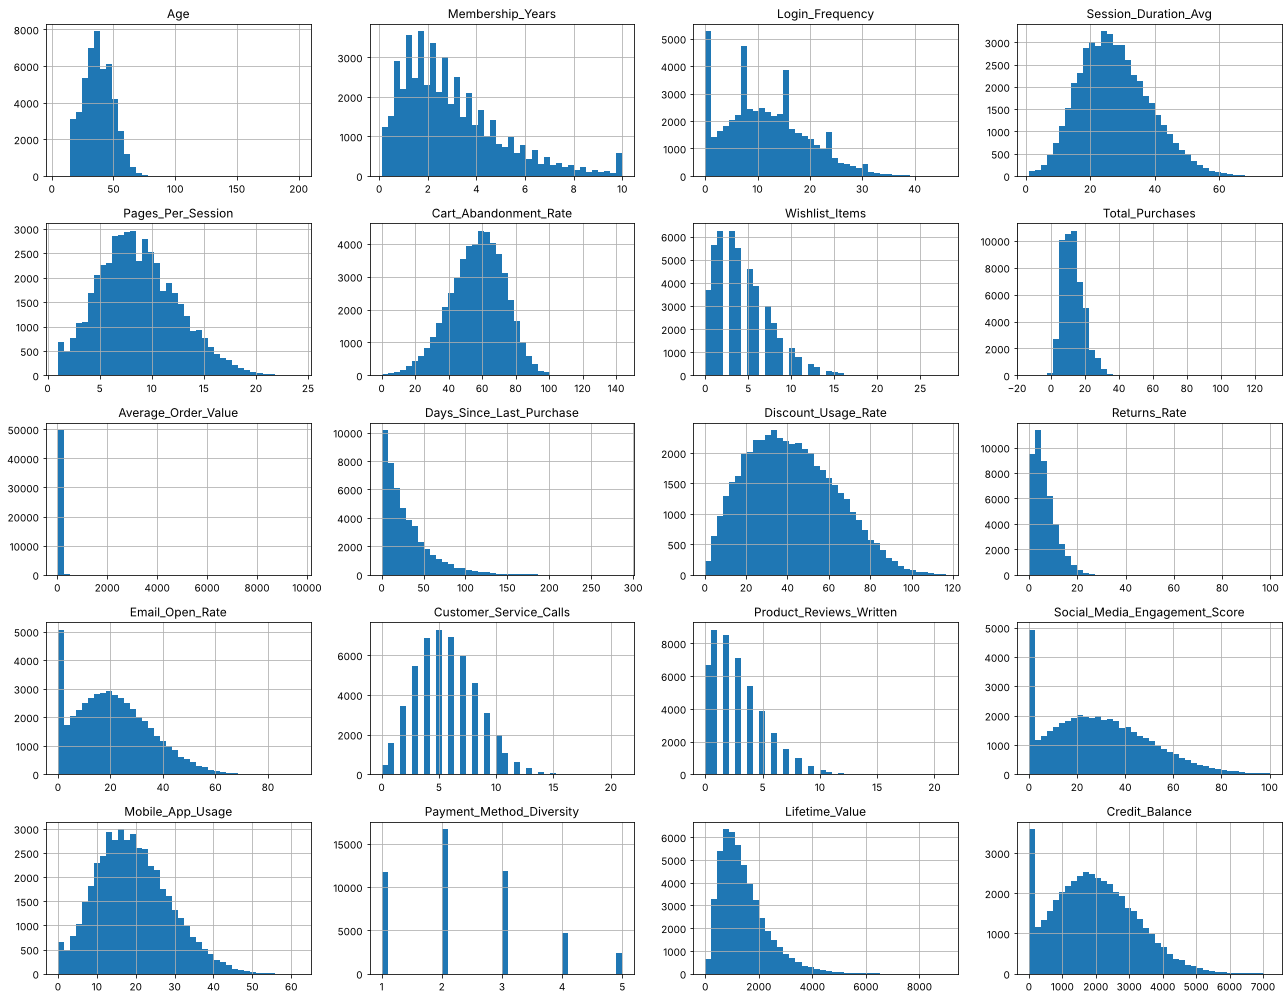

In [6]:
# histogramas de las variables numericas
datos[NUM].hist(figsize=(18, 14), bins=40)
plt.tight_layout()
plt.show()

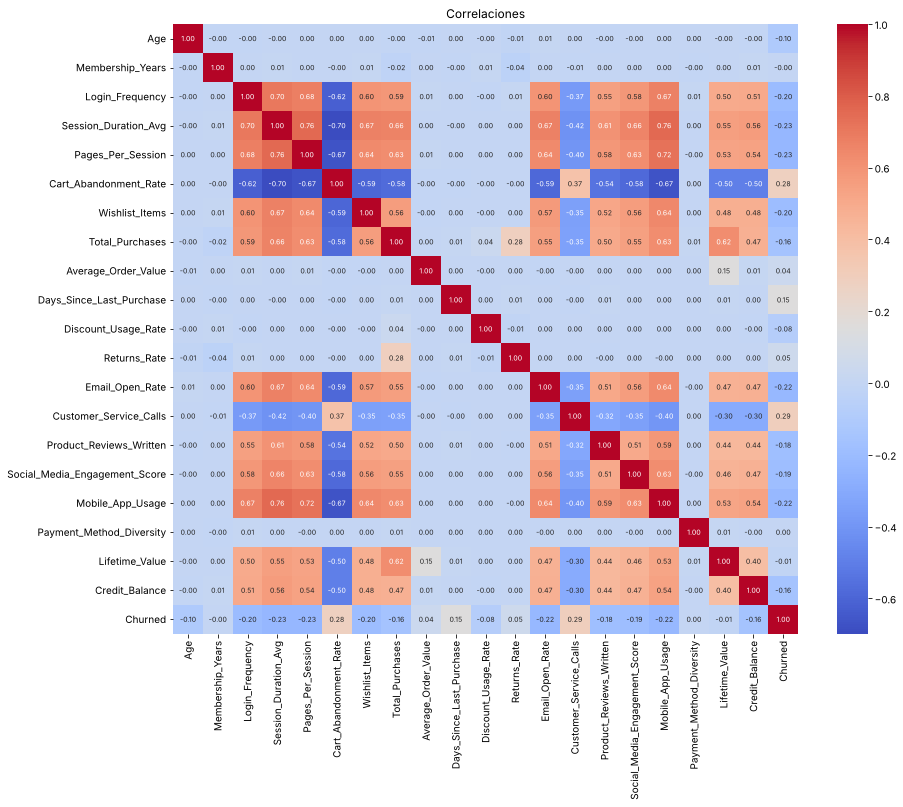

In [7]:
# mapa de calor de correlaciones
corr = datos[NUM + [OBJ]].corr()
plt.figure(figsize=(14, 11))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', annot_kws={'size': 7})
plt.title('Correlaciones')
plt.show()

Varias variables están muy sesgadas a la derecha (compras, ticket promedio, valor de vida, días desde la última compra). Por eso más adelante se transforman con logaritmo. Lifetime_Value se relaciona fuerte con Total_Purchases y Average_Order_Value, porque el valor de vida es más o menos compras por ticket promedio. Esa relación es la que se usa para encontrar errores escondidos.

# Parte 4. División 80/20 antes de limpiar
Primero se separa el test y después se limpia. Si se limpiara todo junto, las medianas y los umbrales usarían información del test y el modelo se vería mejor de lo que es (fuga de información o data leakage). Es la regla que pidió el profesor.

Se usa una división estratificada para que train y test tengan la misma proporción de churn. Con la semilla 42 sale exactamente la misma división que ya usamos en SAS (40,000 y 10,000 clientes).

In [8]:
train_crudo, test_crudo = train_test_split(datos, test_size=0.2, stratify=datos[OBJ], random_state=SEMILLA)
train_txt = datos_txt.loc[train_crudo.index]
test_txt = datos_txt.loc[test_crudo.index]

print('Train:', train_crudo.shape, f"churn {train_crudo[OBJ].mean():.1%}")
print('Test: ', test_crudo.shape, f"churn {test_crudo[OBJ].mean():.1%}")

# copias que se van a limpiar; los crudos se quedan igual para comparar
train = train_crudo.copy()
test = test_crudo.copy()
bitacora = []

def anotar(variable, regla, filas_train, filas_test):
    bitacora.append({'variable': variable, 'regla': regla, 'filas train': int(filas_train), 'filas test': int(filas_test)})
    print(f'{variable}: {regla} -> train {int(filas_train)}, test {int(filas_test)}')

def decimales(serie_txt):
    # cuenta los digitos despues del punto: '16.900000000000002' -> 15
    return serie_txt.str.split('.').str[1].str.len().fillna(0).astype(int)

Train: (40000, 25) churn 28.9%
Test:  (10000, 25) churn 28.9%


# Parte 5. Limpieza variable por variable
Cada regla se decide viendo solo el train y después se aplica igual a los dos conjuntos. Los umbrales y las medianas salen del train. En el test no se calcula nada.

Los valores imposibles se vuelven faltantes y al final se imputan con la mediana del train. Los valores que alguien multiplicó por un factor se regresan a su valor original dividiendo entre ese factor.

## 5.1 Age
Un cliente debe tener 18 años o más y nadie vive más de 100. Las edades de 5, 10, 150 y 200 son errores de captura. No se usa clip, porque convertiría una edad de 200 en 80 e inventaría un cliente de 80 años. Esas edades pasan a faltante y se imputan en el paso 5.9.

In [9]:
f_tr = (train['Age'] < 18) | (train['Age'] > 100)
f_te = (test['Age'] < 18) | (test['Age'] > 100)
print('Edades imposibles en train:', sorted(train.loc[f_tr, 'Age'].unique().tolist()))
train.loc[f_tr, 'Age'] = np.nan
test.loc[f_te, 'Age'] = np.nan
anotar('Age', 'fuera de 18-100 -> faltante', f_tr.sum(), f_te.sum())

Edades imposibles en train: [5.0, 10.0, 150.0, 200.0]
Age: fuera de 18-100 -> faltante -> train 42, test 8


## 5.2 Average_Order_Value (marcar los inflados)
Se ordenan los valores del train y se busca el salto más grande entre un valor y el siguiente. Arriba de ese salto están los valores inflados (entre 5,000 y 9,700, cuando el resto llega a unos 400). Aquí solo se marcan. Se corrigen en el paso 5.5, cuando Total_Purchases ya esté bien.

In [10]:
orden = np.sort(train['Average_Order_Value'].dropna().values)
saltos = orden[1:] / orden[:-1]
k = saltos.argmax()
UMBRAL_AOV = orden[k]      # calculado solo con train
print(f'Salto más grande: de {orden[k]:.2f} a {orden[k+1]:.2f} (x{saltos[k]:.1f})')

aov_tr = train['Average_Order_Value'] > UMBRAL_AOV
aov_te = test['Average_Order_Value'] > UMBRAL_AOV
print('Valores inflados -> train:', aov_tr.sum(), '| test:', aov_te.sum())

Salto más grande: de 397.85 a 5043.22 (x12.7)
Valores inflados -> train: 22 | test: 3


## 5.3 Total_Purchases (dividir entre 1.3)
Total_Purchases es un conteo y debería ser entero. Unos 9,000 valores del train traen decimales, y todos son múltiplos exactos de 1.3. Además, el valor de vida (Lifetime_Value) debería ser más o menos compras por ticket promedio. En las filas con decimales esa relación da 0.77 (1 entre 1.3) en lugar de 1. Eso confirma que a esas compras se les multiplicó por 1.3.

También hay casos escondidos: 10 compras por 1.3 dan 13, que es entero. Por eso, los valores de 13, 26, 39, etc. con la relación por debajo de 0.8 también se dividen entre 1.3. En las filas sanas la relación casi nunca baja de 0.8.

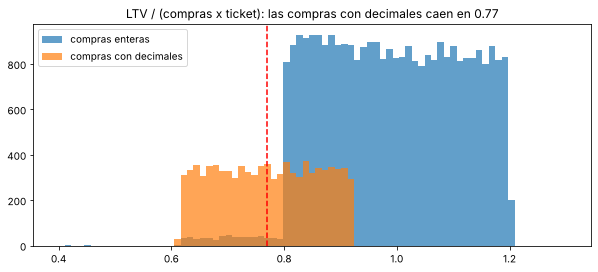

In [11]:
def cociente(df):
    return df['Lifetime_Value'] / (df['Total_Purchases'] * df['Average_Order_Value'])

# antes de corregir: la relacion LTV / (TP x AOV) tiene dos montañas
c0 = cociente(train)
dec = train['Total_Purchases'] % 1 != 0
ok = (train['Total_Purchases'] > 0) & ~aov_tr
plt.figure(figsize=(10, 4))
plt.hist(c0[ok & ~dec], bins=np.linspace(0.4, 1.3, 80), alpha=0.7, label='compras enteras')
plt.hist(c0[ok & dec], bins=np.linspace(0.4, 1.3, 80), alpha=0.7, label='compras con decimales')
plt.axvline(1 / 1.3, color='red', ls='--')
plt.title('LTV / (compras x ticket): las compras con decimales caen en 0.77')
plt.legend()
plt.show()

In [12]:
LIMITE_COCIENTE = 0.8

def corregir_compras(df, aov_inflado):
    tp = df['Total_Purchases']
    c = cociente(df)
    a = tp % 1 != 0                                                   # con decimales
    b = (tp % 1 == 0) & (tp > 0) & (tp % 13 == 0) & (c < LIMITE_COCIENTE) & ~aov_inflado   # escondidos
    df.loc[a | b, 'Total_Purchases'] = (tp[a | b] / 1.3).round()
    return a, b

a_tr, b_tr = corregir_compras(train, aov_tr)
a_te, b_te = corregir_compras(test, aov_te)
anotar('Total_Purchases', 'con decimales / 1.3', a_tr.sum(), a_te.sum())
anotar('Total_Purchases', '13, 26, 39... con relación < 0.8 / 1.3', b_tr.sum(), b_te.sum())

c1 = cociente(train)
print(f'Filas con relación < 0.8 -> antes {(c0[ok] < 0.8).mean():.1%} | después {(c1[ok] < 0.8).mean():.2%}')

Total_Purchases: con decimales / 1.3 -> train 9019, test 2222
Total_Purchases: 13, 26, 39... con relación < 0.8 / 1.3 -> train 595, test 149
Filas con relación < 0.8 -> antes 15.1% | después 0.21%


## 5.4 Total_Purchases negativos
No se puede comprar un número negativo de veces. Se revisa después del paso anterior (un -10.4 se vuelve -8). Como sigue siendo negativo, pasa a faltante.

In [13]:
f_tr = train['Total_Purchases'] < 0
f_te = test['Total_Purchases'] < 0
train.loc[f_tr, 'Total_Purchases'] = np.nan
test.loc[f_te, 'Total_Purchases'] = np.nan
anotar('Total_Purchases', 'negativo -> faltante', f_tr.sum(), f_te.sum())

Total_Purchases: negativo -> faltante -> train 32, test 8


## 5.5 Average_Order_Value (recalcular los inflados)
Para los valores marcados en 5.2, el ticket promedio real se recalcula con datos de la misma fila: Lifetime_Value entre Total_Purchases (ya corregido). No usa información de otros clientes, así que no hay fuga.

In [14]:
def recalcular_aov(df, marcados):
    nuevo = (df['Lifetime_Value'] / df['Total_Purchases']).round(2).where(df['Total_Purchases'] > 0)
    antes = df.loc[marcados, 'Average_Order_Value'].copy()
    df.loc[marcados, 'Average_Order_Value'] = nuevo[marcados]
    return antes

antes = recalcular_aov(train, aov_tr)
recalcular_aov(test, aov_te)
anotar('Average_Order_Value', f'> {UMBRAL_AOV:.2f} -> LTV / compras', aov_tr.sum(), aov_te.sum())
pd.DataFrame({'antes': antes.round(2), 'después': train.loc[aov_tr, 'Average_Order_Value']}).head()

Average_Order_Value: > 397.85 -> LTV / compras -> train 22, test 3


,antes,después
38534,9273.53,76.45
16297,9146.00,147.59
41673,5043.22,84.86
16969,7339.54,90.41
15588,8507.21,210.00


## 5.6 Discount_Usage_Rate (dividir entre 1.2)
Los datos originales traen 1 decimal. Unos 7,600 valores del train traen 2 o más, o pasan de 100%. Al dividirlos entre 1.2 todos regresan a 1 decimal exacto y su distribución queda igual a la de los valores sanos. Se corrigen esos valores.

Limitación: si el original terminaba en .0 o .5, el valor multiplicado sigue con 1 decimal y no se puede detectar (salvo que pase de 100). Además, en este archivo unos 90 valores del train ya vienen redondeados y perdieron la pista de los decimales.

Discount_Usage_Rate: 2+ decimales o > 100 -> / 1.2 -> train 7513, test 1814
Máximo antes 116.64 | después 99.60


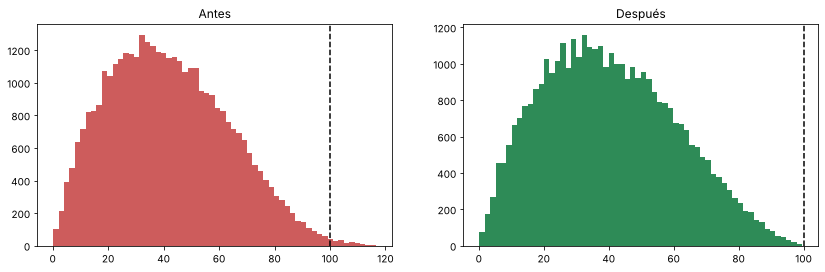

In [15]:
def corregir_descuento(df, df_txt):
    d = df['Discount_Usage_Rate']
    f = d.notna() & ((decimales(df_txt['Discount_Usage_Rate']) >= 2) | (d > 100))
    df.loc[f, 'Discount_Usage_Rate'] = (d[f] / 1.2).round(1)
    return f

d0 = train['Discount_Usage_Rate'].copy()
f_tr = corregir_descuento(train, train_txt)
f_te = corregir_descuento(test, test_txt)
anotar('Discount_Usage_Rate', '2+ decimales o > 100 -> / 1.2', f_tr.sum(), f_te.sum())
print(f"Máximo antes {d0.max():.2f} | después {train['Discount_Usage_Rate'].max():.2f}")

fig, axs = plt.subplots(1, 2, figsize=(14, 4))
axs[0].hist(d0.dropna(), bins=60, color='indianred'); axs[0].axvline(100, color='k', ls='--')
axs[0].set_title('Antes')
axs[1].hist(train['Discount_Usage_Rate'].dropna(), bins=60, color='seagreen'); axs[1].axvline(100, color='k', ls='--')
axs[1].set_title('Después')
plt.show()

## 5.7 Cart_Abandonment_Rate
Nadie puede abandonar más del 100% de sus carritos. Los valores mayores a 100 pasan a faltante.

In [16]:
f_tr = train['Cart_Abandonment_Rate'] > 100
f_te = test['Cart_Abandonment_Rate'] > 100
train.loc[f_tr, 'Cart_Abandonment_Rate'] = np.nan
test.loc[f_te, 'Cart_Abandonment_Rate'] = np.nan
anotar('Cart_Abandonment_Rate', '> 100 -> faltante', f_tr.sum(), f_te.sum())

Cart_Abandonment_Rate: > 100 -> faltante -> train 22, test 8


## 5.8 Returns_Rate y Membership_Years
Hay unas filas donde estas dos columnas traen 3 o más decimales al mismo tiempo, cuando el resto trae 1. En esas filas Returns_Rate va de 80% a 99%, y ningún otro cliente pasa de 40%. Son datos inventados. No se puede saber el valor real, así que las dos celdas pasan a faltante.

In [17]:
def filas_inventadas(df_txt):
    return (decimales(df_txt['Returns_Rate']) >= 3) & (decimales(df_txt['Membership_Years']) >= 3)

f_tr = filas_inventadas(train_txt)
f_te = filas_inventadas(test_txt)
print(f"Returns_Rate en esas filas: {train.loc[f_tr, 'Returns_Rate'].min():.1f} a {train.loc[f_tr, 'Returns_Rate'].max():.1f}")
train.loc[f_tr, ['Returns_Rate', 'Membership_Years']] = np.nan
test.loc[f_te, ['Returns_Rate', 'Membership_Years']] = np.nan
anotar('Returns_Rate y Membership_Years', '3+ decimales a la vez -> faltante', f_tr.sum(), f_te.sum())

Returns_Rate en esas filas: 80.2 a 99.6
Returns_Rate y Membership_Years: 3+ decimales a la vez -> faltante -> train 85, test 15


## 5.9 Variables que se revisaron y no se cambian
- Login_Frequency, Session_Duration_Avg, Pages_Per_Session, Wishlist_Items, Days_Since_Last_Purchase, Email_Open_Rate, Customer_Service_Calls, Product_Reviews_Written, Social_Media_Engagement_Score, Mobile_App_Usage, Payment_Method_Diversity, Lifetime_Value y Credit_Balance: están en rangos posibles, sin decimales raros ni saltos. Solo tienen faltantes.
- Los valores altos pero continuos (por ejemplo, Lifetime_Value mayor a 5,000) son clientes reales extremos, no errores. El logaritmo reduce su peso.
- Unos 400 clientes tendrían antigüedad desde antes de los 13 años. No se sabe cuál de las dos columnas está mal, así que no se tocan.
- Las categóricas (Gender, Country, City, Signup_Quarter) no tienen errores de escritura y tienen las mismas categorías en train y test.

In [18]:
# comprobacion de rangos en train despues de las correcciones
revisar = ['Age', 'Total_Purchases', 'Average_Order_Value', 'Discount_Usage_Rate',
           'Cart_Abandonment_Rate', 'Returns_Rate', 'Membership_Years']
pd.DataFrame({'mín crudo': train_crudo[revisar].min(), 'mín limpio': train[revisar].min(),
              'máx crudo': train_crudo[revisar].max(), 'máx limpio': train[revisar].max()}).round(2)

,mín crudo,mín limpio,máx crudo,máx limpio
Age,5.00,18.00,200.00,75.00
Total_Purchases,-13.00,0.00,128.70,99.00
Average_Order_Value,26.38,26.38,9666.38,397.85
Discount_Usage_Rate,0.24,0.20,116.64,99.60
Cart_Abandonment_Rate,0.00,0.00,143.74,100.00
Returns_Rate,0.00,0.00,99.62,39.40
Membership_Years,0.10,0.10,10.00,10.00


## 5.10 Imputación con la mediana del train
Todos los faltantes (los originales y los que se crearon con las reglas) se rellenan con la mediana calculada en train. Se usa la mediana porque no se mueve con los valores extremos. En Age, la mediana es 38, el mismo valor que la media redondeada.

En el test se usan esas mismas medianas del train. No se calcula nada con el test, así que no hay fuga de información. Así los cinco modelos reciben una tabla completa.

In [19]:
medianas = train[NUM].median()      # solo con train
falt_tr = train[NUM].isnull().sum()
falt_te = test[NUM].isnull().sum()

tabla = pd.DataFrame({'faltantes train': falt_tr, 'faltantes test': falt_te, 'mediana del train': medianas})
tabla = tabla[(tabla['faltantes train'] > 0) | (tabla['faltantes test'] > 0)]
for v in tabla.index:
    anotar(v, f'imputar con mediana ({medianas[v]})', falt_tr[v], falt_te[v])

train[NUM] = train[NUM].fillna(medianas)
test[NUM] = test[NUM].fillna(medianas)
print()
print('Faltantes que quedan -> train:', int(train.isnull().sum().sum()), '| test:', int(test.isnull().sum().sum()))

Age: imputar con mediana (38.0) -> train 2020, test 525
Membership_Years: imputar con mediana (2.5) -> train 85, test 15
Session_Duration_Avg: imputar con mediana (26.8) -> train 2689, test 710
Pages_Per_Session: imputar con mediana (8.4) -> train 2359, test 641
Cart_Abandonment_Rate: imputar con mediana (58.1) -> train 22, test 8
Wishlist_Items: imputar con mediana (4.0) -> train 3210, test 790
Total_Purchases: imputar con mediana (12.0) -> train 32, test 8
Days_Since_Last_Purchase: imputar con mediana (21.0) -> train 2412, test 588
Discount_Usage_Rate: imputar con mediana (38.8) -> train 2828, test 672
Returns_Rate: imputar con mediana (5.4) -> train 3695, test 896
Email_Open_Rate: imputar con mediana (19.7) -> train 2018, test 510
Customer_Service_Calls: imputar con mediana (5.0) -> train 140, test 28
Product_Reviews_Written: imputar con mediana (2.0) -> train 2772, test 728
Social_Media_Engagement_Score: imputar con mediana (27.6) -> train 4765, test 1235
Mobile_App_Usage: imputar 

## 5.11 Resumen de la limpieza

In [20]:
resumen = pd.DataFrame(bitacora)
resumen

,variable,regla,filas train,filas test
0,Age,fuera de 18-100 -> faltante,42,8
1,Total_Purchases,con decimales / 1.3,9019,2222
2,Total_Purchases,"13, 26, 39... con relación < 0.8 / 1.3",595,149
3,Total_Purchases,negativo -> faltante,32,8
4,Average_Order_Value,> 397.85 -> LTV / compras,22,3
5,Discount_Usage_Rate,2+ decimales o > 100 -> / 1.2,7513,1814
6,Cart_Abandonment_Rate,> 100 -> faltante,22,8
7,Returns_Rate y Membership_Years,3+ decimales a la vez -> faltante,85,15
8,Age,imputar con mediana (38.0),2020,525
9,Membership_Years,imputar con mediana (2.5),85,15


# Parte 6. Transformación logarítmica log(x+1)
Ocho variables tienen mucho sesgo a la derecha: Membership_Years, Wishlist_Items, Total_Purchases, Average_Order_Value, Days_Since_Last_Purchase, Returns_Rate, Product_Reviews_Written y Lifetime_Value. Se transforman con log(x+1), que comprime los valores altos y deja la distribución más simétrica. Se suma 1 porque log(0) no existe y varias variables tienen ceros. La columna nueva log_X reemplaza a la original.

Se aplica igual en train y en test. Si el test se dejara en la escala original, el modelo recibiría números en otra escala y su rendimiento se caería.

In [21]:
VARS_LOG = ['Membership_Years', 'Wishlist_Items', 'Total_Purchases', 'Average_Order_Value',
            'Days_Since_Last_Purchase', 'Returns_Rate', 'Product_Reviews_Written', 'Lifetime_Value']

def transformar_log(df):
    d = df.copy()
    for c in VARS_LOG:
        d[c] = np.log1p(d[c])
    return d.rename(columns={c: 'log_' + c for c in VARS_LOG})

train_log = transformar_log(train)
test_log = transformar_log(test)

sesgo = pd.DataFrame({'sesgo antes': [train[c].skew() for c in VARS_LOG],
                      'sesgo después': [train_log['log_' + c].skew() for c in VARS_LOG]}, index=VARS_LOG).round(2)
print('¿Mismas columnas en train y test?', list(train_log.columns) == list(test_log.columns))
sesgo

¿Mismas columnas en train y test? True


,sesgo antes,sesgo después
Membership_Years,1.14,0.02
Wishlist_Items,1.01,-0.58
Total_Purchases,2.60,-0.50
Average_Order_Value,0.90,-0.15
Days_Since_Last_Purchase,2.09,-0.56
Returns_Rate,1.26,-0.32
Product_Reviews_Written,1.14,-0.30
Lifetime_Value,1.45,-0.61


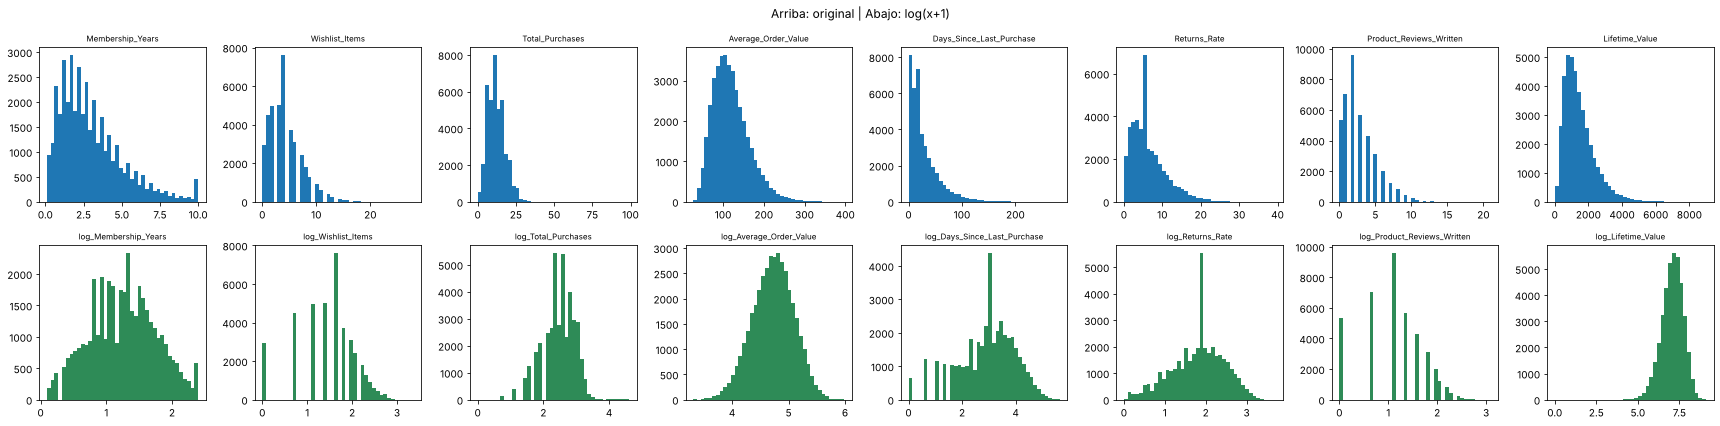

In [22]:
fig, axs = plt.subplots(2, 8, figsize=(24, 6))
for i, c in enumerate(VARS_LOG):
    axs[0, i].hist(train[c], bins=40); axs[0, i].set_title(c, fontsize=8)
    axs[1, i].hist(train_log['log_' + c], bins=40, color='seagreen'); axs[1, i].set_title('log_' + c, fontsize=8)
plt.suptitle('Arriba: original | Abajo: log(x+1)')
plt.tight_layout()
plt.show()

In [23]:
# guardar los datos limpios y transformados con coma decimal, igual que los que se suben a SAS
train_log.to_csv('train_limpio_log.csv', index=False, decimal=',')
test_log.to_csv('test_limpio_log.csv', index=False, decimal=',')
print('Archivos guardados: train_limpio_log.csv y test_limpio_log.csv')

Archivos guardados: train_limpio_log.csv y test_limpio_log.csv


# Parte 7. Variables de entrada, codificación y escalado
Se usan las mismas 11 variables del modelo final de SAS. En Model Studio se quitaron las demás en dos rondas porque casi no aportaban al gradient boosting. Las que no se usan en train tampoco se usan en test.

City es categórica, así que se convierte en columnas de 0 y 1 (one-hot encoding). Después se estandarizan las variables, como en clase, para que todas tengan una escala parecida. Esto lo necesitan la regresión logística y la red neuronal. A los árboles no les afecta. El escalador se ajusta solo con train.

In [24]:
NUMERICAS = ['log_Lifetime_Value', 'Cart_Abandonment_Rate', 'Customer_Service_Calls', 'Discount_Usage_Rate',
             'log_Days_Since_Last_Purchase', 'Age', 'Email_Open_Rate', 'log_Total_Purchases',
             'log_Returns_Rate', 'Pages_Per_Session']
CATEGORICAS = ['City']

X_train = pd.get_dummies(train_log[NUMERICAS + CATEGORICAS], columns=CATEGORICAS, dtype=int)
X_test = pd.get_dummies(test_log[NUMERICAS + CATEGORICAS], columns=CATEGORICAS, dtype=int)
X_test = X_test.reindex(columns=X_train.columns, fill_value=0)     # mismas columnas que train
Y_train = train_log[OBJ]
Y_test = test_log[OBJ]

escalador = StandardScaler().fit(X_train)       # se ajusta solo con train
X_train = pd.DataFrame(escalador.transform(X_train), columns=X_train.columns)
X_test = pd.DataFrame(escalador.transform(X_test), columns=X_test.columns)

print('X_train:', X_train.shape, '| X_test:', X_test.shape)

X_train: (40000, 50) | X_test: (10000, 50)


# Parte 8. Los cinco modelos y validación cruzada
Son los mismos modelos de SAS Model Studio:
- Regresión logística: modelo lineal; da la probabilidad con una función sigmoide.
- Árbol de decisión: reglas tipo "si carrito abandonado > X y llamadas > Y". Se limita la profundidad para que no memorice el train.
- Bosque aleatorio: muchos árboles con muestras y variables al azar. Se promedian sus votos.
- Red neuronal (MLP): una capa oculta de 32 neuronas, con paro temprano para no sobreajustar.
- Gradient boosting: árboles pequeños en secuencia; cada uno corrige los errores del anterior. Fue el campeón en SAS.

Igual que en clase, cada modelo se evalúa con validación cruzada de 10 grupos (KFold) dentro del train. Se usa cross_validate en lugar de cross_val_score porque mide varias métricas en una sola pasada: accuracy, precision, recall, F1, AUC y KS (se explican en la Parte 9). Esta celda tarda unos minutos.

In [25]:
models = []
models.append(('Regresión logística', LogisticRegression(max_iter=1000)))
models.append(('Árbol de decisión', DecisionTreeClassifier(criterion='gini', max_depth=6, min_samples_leaf=50, random_state=SEMILLA)))
models.append(('Bosque aleatorio', RandomForestClassifier(n_estimators=200, min_samples_leaf=5, n_jobs=-1, random_state=SEMILLA)))
models.append(('Red neuronal', MLPClassifier(hidden_layer_sizes=(32,), max_iter=500, early_stopping=True, random_state=SEMILLA)))
models.append(('Gradient Boosting', HistGradientBoostingClassifier(max_iter=300, learning_rate=0.05, random_state=SEMILLA)))

In [26]:
def ks(y, prob):
    # maxima separacion entre la curva de los que se van y la de los que se quedan
    fpr, tpr, _ = roc_curve(y, prob)
    return np.max(tpr - fpr)

metricas_cv = {'accuracy': 'accuracy', 'precision': 'precision', 'recall': 'recall', 'f1': 'f1',
               'roc_auc': 'roc_auc', 'ks': make_scorer(ks, response_method='predict_proba')}

results = []
results_auc = []
names = []
validacion = {}

for name, model in models:
    kfold = KFold(n_splits=10, random_state=SEMILLA, shuffle=True)
    cv = cross_validate(model, X_train, Y_train, cv=kfold, scoring=metricas_cv)
    names.append(name)
    results.append(cv['test_accuracy'])
    results_auc.append(cv['test_roc_auc'])
    validacion[name] = {m: cv['test_' + m].mean() for m in metricas_cv}

for i in range(len(names)):
    print(f'{names[i]:<20} accuracy {results[i].mean():.4f} | AUC {results_auc[i].mean():.4f}')

Regresión logística  accuracy 0.7650 | AUC 0.7676
Árbol de decisión    accuracy 0.8785 | AUC 0.8949
Bosque aleatorio     accuracy 0.9079 | AUC 0.9203
Red neuronal         accuracy 0.8748 | AUC 0.8987
Gradient Boosting    accuracy 0.9129 | AUC 0.9230


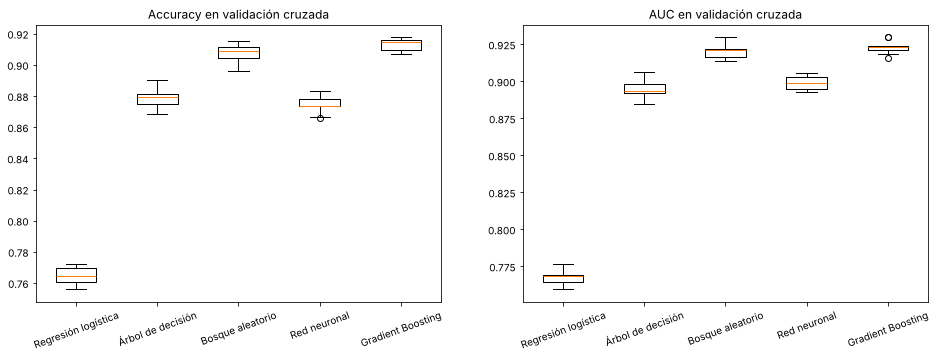

In [27]:
# visualizacion de resultados para compararlos
fig, axs = plt.subplots(1, 2, figsize=(16, 5))
axs[0].boxplot(results); axs[0].set_xticklabels(names, rotation=20); axs[0].set_title('Accuracy en validación cruzada')
axs[1].boxplot(results_auc); axs[1].set_xticklabels(names, rotation=20); axs[1].set_title('AUC en validación cruzada')
plt.show()

# Parte 9. Evaluación en el test (20%)
Cada modelo se entrena con todo el train y se califica con el test, que no participó en nada de lo anterior. Se usa el corte de 0.5, la misma regla de decisión de SAS Intelligent Decisioning: si la probabilidad de churn es mayor a 0.5, el cliente recibe la campaña.

Métricas:
- Accuracy: porcentaje de clientes bien clasificados.
- Precision: de los que el modelo marca como "se va", cuántos sí se fueron.
- Recall: de los que sí se fueron, cuántos detectó el modelo.
- F1: balance entre precision y recall.
- AUC: área bajo la curva ROC. Mide qué tan bien ordena a los clientes por riesgo (0.5 es al azar y 1 es perfecto).
- KS: máxima separación entre la curva de los que se van y la de los que se quedan. Es la métrica que usa SAS para elegir al campeón.

In [28]:
CORTE = 0.5
predicciones = {}
probabilidades = {}

for name, model in models:
    model.fit(X_train, Y_train)
    probabilidades[name] = model.predict_proba(X_test)[:, 1]
    predicciones[name] = (probabilidades[name] > CORTE).astype(int)

    print('Precisión del test para', name)
    print(accuracy_score(Y_test, predicciones[name]))
    print(classification_report(Y_test, predicciones[name]))

Precisión del test para Regresión logística
0.7654
              precision    recall  f1-score   support

           0       0.79      0.92      0.85      7110
           1       0.66      0.39      0.49      2890

    accuracy                           0.77     10000
   macro avg       0.72      0.65      0.67     10000
weighted avg       0.75      0.77      0.74     10000

Precisión del test para Árbol de decisión
0.8803
              precision    recall  f1-score   support

           0       0.88      0.96      0.92      7110
           1       0.88      0.68      0.77      2890

    accuracy                           0.88     10000
   macro avg       0.88      0.82      0.84     10000
weighted avg       0.88      0.88      0.88     10000

Precisión del test para Bosque aleatorio
0.9098
              precision    recall  f1-score   support

           0       0.91      0.97      0.94      7110
           1       0.91      0.77      0.83      2890

    accuracy                      

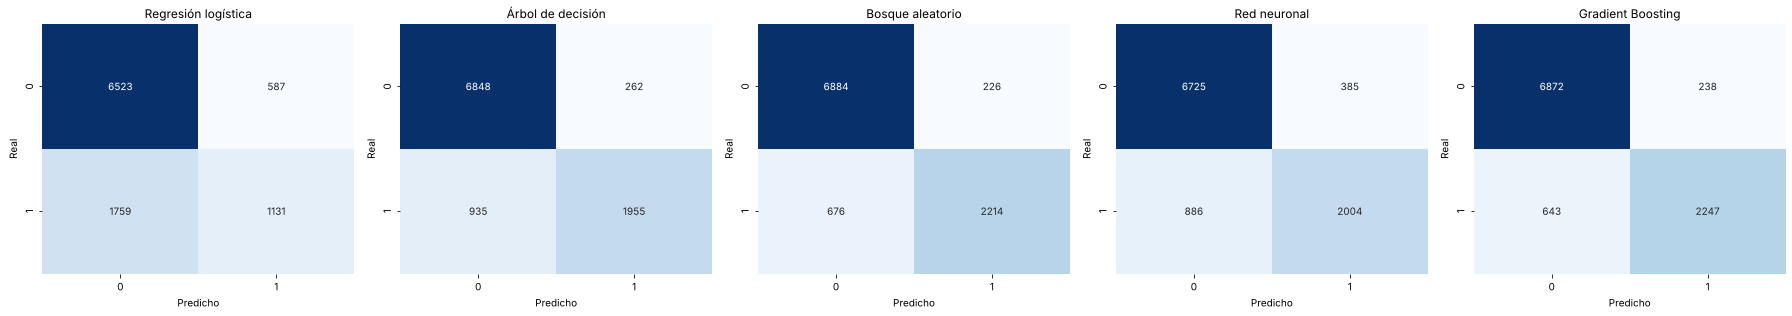

In [29]:
# matrices de confusion: filas = real, columnas = predicho
label = ['0', '1']
fig, axs = plt.subplots(1, 5, figsize=(25, 4.5))
for ax, name in zip(axs, names):
    sns.heatmap(confusion_matrix(Y_test, predicciones[name]), annot=True, fmt='d',
                xticklabels=label, yticklabels=label, cmap='Blues', ax=ax, cbar=False)
    ax.set_title(name); ax.set_xlabel('Predicho'); ax.set_ylabel('Real')
plt.tight_layout()
plt.show()

In [30]:
comparativa = pd.DataFrame({
    'Accuracy': [accuracy_score(Y_test, predicciones[n]) for n in names],
    'Precision': [precision_score(Y_test, predicciones[n]) for n in names],
    'Recall': [recall_score(Y_test, predicciones[n]) for n in names],
    'F1': [f1_score(Y_test, predicciones[n]) for n in names],
    'AUC': [roc_auc_score(Y_test, probabilidades[n]) for n in names],
    'KS': [ks(Y_test, probabilidades[n]) for n in names],
    'Accuracy CV': [r.mean() for r in results],
    'AUC CV': [r.mean() for r in results_auc]}, index=names).sort_values('AUC CV', ascending=False)
comparativa.round(4)

,Accuracy,Precision,Recall,F1,AUC,KS,Accuracy CV,AUC CV
Gradient Boosting,0.9119,0.9042,0.7775,0.8361,0.9244,0.7713,0.9129,0.9230
Bosque aleatorio,0.9098,0.9074,0.7661,0.8308,0.9244,0.7661,0.9079,0.9203
Red neuronal,0.8729,0.8388,0.6934,0.7592,0.9019,0.6962,0.8748,0.8987
Árbol de decisión,0.8803,0.8818,0.6765,0.7656,0.8980,0.6860,0.8785,0.8949
Regresión logística,0.7654,0.6583,0.3913,0.4909,0.7718,0.4100,0.7650,0.7676


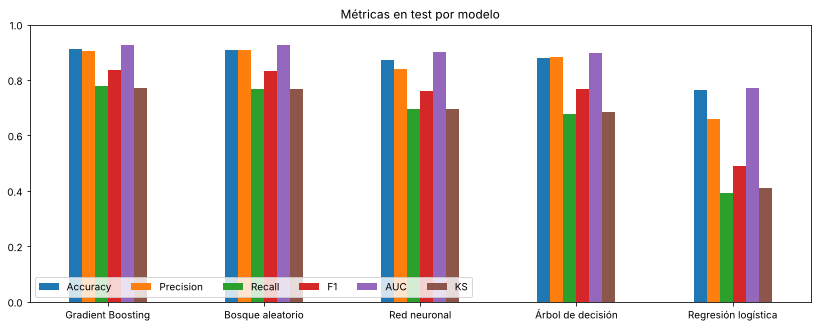

In [31]:
comparativa[['Accuracy', 'Precision', 'Recall', 'F1', 'AUC', 'KS']].plot(kind='bar', figsize=(14, 5), rot=0)
plt.title('Métricas en test por modelo')
plt.ylim(0, 1)
plt.legend(loc='lower left', ncol=6)
plt.show()

# Parte 10. Curva ROC
La curva ROC muestra, para todos los cortes posibles, cuántos de los que se van detecta el modelo (verdaderos positivos, eje y) contra cuántos de los que se quedan marca por error (falsos positivos, eje x). Mientras más se pegue a la esquina de arriba a la izquierda, mejor. La diagonal es un modelo al azar.

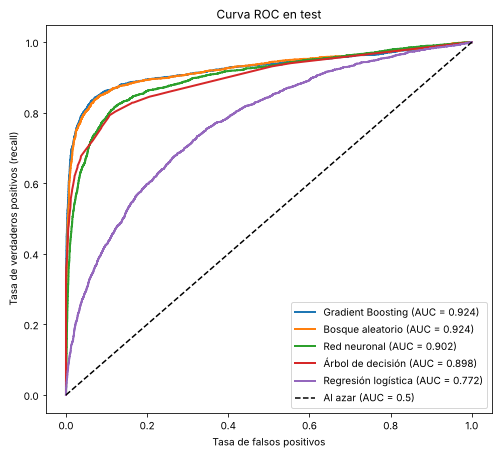

In [32]:
plt.figure(figsize=(8, 7))
for name in comparativa.index:
    fpr, tpr, _ = roc_curve(Y_test, probabilidades[name])
    plt.plot(fpr, tpr, lw=2, label=f"{name} (AUC = {comparativa.loc[name, 'AUC']:.3f})")
plt.plot([0, 1], [0, 1], 'k--', label='Al azar (AUC = 0.5)')
plt.xlabel('Tasa de falsos positivos')
plt.ylabel('Tasa de verdaderos positivos (recall)')
plt.title('Curva ROC en test')
plt.legend(loc='lower right')
plt.show()

# Parte 11. Modelo campeón: gradient boosting
Se confirma al campeón con la validación cruzada (AUC) y se revisa que en el test diga lo mismo. Abajo se compara con los resultados de SAS Model Studio. Los de SAS son de su partición de validación (30% del train), así que se esperan números parecidos pero no idénticos.

In [33]:
campeon = max(names, key=lambda n: comparativa.loc[n, 'AUC CV'])
print('Campeón por AUC en validación cruzada:', campeon)

sas = pd.DataFrame({'Accuracy': [0.9169, 0.9029], 'AUC': [0.9234, 0.9170], 'KS': [0.7734, 0.7409]},
                   index=['Gradient Boosting', 'Bosque aleatorio'])
python_test = comparativa.loc[['Gradient Boosting', 'Bosque aleatorio'], ['Accuracy', 'AUC', 'KS']]
pd.concat({'SAS (validación)': sas, 'Python (test)': python_test}, axis=1).round(4)

Campeón por AUC en validación cruzada: Gradient Boosting


SAS (validación)                 Python (test)          \
                          Accuracy     AUC      KS      Accuracy     AUC   
Gradient Boosting           0.9169  0.9234  0.7734        0.9119  0.9244   
Bosque aleatorio            0.9029  0.9170  0.7409        0.9098  0.9244   

                           
                       KS  
Gradient Boosting  0.7713  
Bosque aleatorio   0.7661

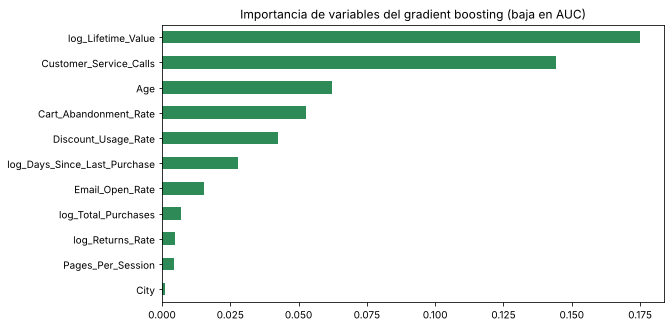

In [34]:
# que variables usa mas el gradient boosting: se revuelve una variable a la vez y se mide cuanto baja el AUC
gb = dict(models)['Gradient Boosting']
imp = permutation_importance(gb, X_test, Y_test, scoring='roc_auc', n_repeats=5, random_state=SEMILLA)
importancia = pd.Series(imp.importances_mean, index=X_test.columns)

# las columnas de City se suman en una sola variable
importancia = importancia.groupby(lambda c: 'City' if c.startswith('City_') else c).sum().sort_values()
importancia.plot(kind='barh', figsize=(9, 5), color='seagreen')
plt.title('Importancia de variables del gradient boosting (baja en AUC)')
plt.show()

# Parte 12. Guardar resultados para el dashboard
Se guardan los archivos que lee la pestaña de comparativa de modelos en Streamlit (carpeta data/modelos del repositorio):
- comparativa_modelos.csv: métricas de los cinco modelos en validación cruzada y en test.
- roc_modelos.csv: puntos de la curva ROC de cada modelo en test.
- importancia_gb.csv: importancia de variables del gradient boosting.
- resumen_campeon.json: métricas y matriz de confusión del campeón en test.
Los datos limpios de la Parte 6 se suben al repositorio como train_log.csv y test_log.csv.

In [35]:
nombres = {'accuracy': 'Accuracy', 'precision': 'Precisión', 'recall': 'Recall', 'f1': 'F1', 'roc_auc': 'AUC', 'ks': 'KS'}
filas = []
for name in names:
    val = {nombres[m]: v for m, v in validacion[name].items()}
    tes = {'Accuracy': accuracy_score(Y_test, predicciones[name]), 'Precisión': precision_score(Y_test, predicciones[name]),
           'Recall': recall_score(Y_test, predicciones[name]), 'F1': f1_score(Y_test, predicciones[name]),
           'AUC': roc_auc_score(Y_test, probabilidades[name]), 'KS': ks(Y_test, probabilidades[name])}
    for particion, m in [('Validación', val), ('Test', tes)]:
        filas.append({'Modelo': name, 'Partición': particion, **m, 'Error de clasificación': 1 - m['Accuracy']})
pd.DataFrame(filas).round(6).to_csv('comparativa_modelos.csv', index=False)

filas = []
for name in names:
    fpr, tpr, cortes = roc_curve(Y_test, probabilidades[name])
    filas.append(pd.DataFrame({'Modelo': name, 'FPR': fpr, 'TPR': tpr, 'Corte': np.minimum(cortes, 1)}))
pd.concat(filas).round(6).to_csv('roc_modelos.csv', index=False)

importancia.sort_values(ascending=False).round(6).rename_axis('Variable').rename('Baja del AUC').to_csv('importancia_gb.csv')

vn, fp, fn, vp = confusion_matrix(Y_test, predicciones['Gradient Boosting']).ravel()
gb_test = comparativa.loc['Gradient Boosting']
resumen_gb = {'campeon': 'Gradient Boosting', 'corte': CORTE, 'semilla': SEMILLA,
              'metricas_test': {'Accuracy': round(gb_test['Accuracy'], 6), 'Precisión': round(gb_test['Precision'], 6),
                                'Recall': round(gb_test['Recall'], 6), 'F1': round(gb_test['F1'], 6),
                                'AUC': round(gb_test['AUC'], 6), 'KS': round(gb_test['KS'], 6),
                                'Error de clasificación': round(1 - gb_test['Accuracy'], 6)},
              'matriz_test': {'VN': int(vn), 'FP': int(fp), 'FN': int(fn), 'VP': int(vp)}}
json.dump(resumen_gb, open('resumen_campeon.json', 'w'), ensure_ascii=False, indent=2)
print('Archivos guardados: comparativa_modelos.csv, roc_modelos.csv, importancia_gb.csv y resumen_campeon.json')

Archivos guardados: comparativa_modelos.csv, roc_modelos.csv, importancia_gb.csv y resumen_campeon.json


# Conclusión
El dataset crudo tenía errores escondidos que la limpieza anterior no detectaba: compras multiplicadas por 1.3, descuentos multiplicados por 1.2, tickets promedio inflados, edades y porcentajes imposibles y filas con devoluciones inventadas. Se corrigieron con reglas calculadas solo con el 80% de entrenamiento. Al test se le aplicaron las mismas reglas y las mismas medianas, sin calcular nada con él. Las 8 variables sesgadas quedaron en logaritmo en los dos conjuntos.

Con las mismas 11 variables del modelo final de SAS, el gradient boosting vuelve a ser el campeón. Tiene el mayor accuracy y AUC en validación cruzada. En el test empata en AUC con el bosque aleatorio (0.924), pero gana en accuracy, recall, F1 y KS, así que detecta más clientes que se van con casi la misma precisión. Sus resultados son muy parecidos a los de SAS (accuracy 0.912 contra 0.917, AUC 0.924 contra 0.923 y KS 0.771 contra 0.773). Los modelos de árboles superan a la regresión logística porque capturan combinaciones como "carrito abandonado alto y muchas llamadas a servicio" sin que se las tengamos que dar. La regresión logística solo traza una frontera lineal.

Limitaciones: los parámetros no se optimizaron con búsqueda en rejilla; unos ~1,850 descuentos multiplicados por 1.2 no se pueden detectar; y la imputación con la mediana crea un pico artificial en el valor imputado.